# 05 · Time-series LSTM extension  *(owner: Archee, with Summaya for evaluation)*

**Question this notebook answers:** does modelling *how the signals change over time* help, compared with (a) summary features + classical models (your main pipeline) and (b) a neural network that sees the same frames but ignores their order?

It uses the **same calibrated per-frame signals and the same windows** as notebook 02 (EAR, MAR, eyebrow, head pitch/yaw; roll left out), the **same 5 subject folds** for every system, and the same metrics, so the comparison is paired.

| System | Input | Sees time order? |
|---|---|---|
| **A** handcrafted ensemble (RF + XGB + MLP) | window summary features (notebook 02) | via hand-made statistics only |
| **B** FrameNet | every frame on its own, then pooled (mean + max) | **no** |
| **C** SeqNet (1-D conv + LSTM) | the full frame sequence | **yes** |
| **D** SeqNet + handcrafted features (extension) | sequence + the window features | yes, plus hand-made statistics |

B vs C is the clean test of *temporal modelling* (same data, same training, only the order-awareness differs). D asks whether learned and hand-made signals are complementary.

**Setup:** `pip install torch --index-url https://download.pytorch.org/whl/cpu` (CPU build, Windows). Run notebook 02 first (it writes `data/signals/`).

**Honest limits:** the sequence models use fixed hyper-parameters (not tuned like notebook 03), the folds are 5-fold subject-grouped (not leave-one-subject-out), and the frames are 15 fps landmark signals, not pixels. This is a *landmark-sequence* model, not a CNN on face images.

In [1]:
import os, json, copy, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import classification_report
from drowsy_utils import *

QUICK      = False   # tiny run, only to check that the notebook works
EPOCHS     = 3 if QUICK else 15
N_THREADS  = 3         # CPU threads for PyTorch
SEED       = 0
FPS_SEQ    = 15        # every video is resampled to this rate
MAX_GAP    = 0.5       # s: farther than this from a valid frame = "missing"
BATCH, HID = 64, 48
RUN_FUSION = True

torch.set_num_threads(N_THREADS); torch.manual_seed(SEED); np.random.seed(SEED)
info = json.load(open("data/run_info.json"))
WIN_S = float(info["win_s"]); T = int(round(WIN_S * FPS_SEQ))
RUN = f'seq_{info["calibration"]}_w{int(WIN_S)}' + ("_quick" if QUICK else "")
RES = f"results/{RUN}"; os.makedirs(RES, exist_ok=True)
print("run:", RUN, "| window", WIN_S, "s ->", T, "steps | settings from notebook 02:", info)

df, groups = load_windows()
df = df.merge(pd.read_csv("data/subject_folds.csv", dtype={"subject": str}), on="subject")
FEATS = feature_list(groups, list(groups))
y, subj, N = df.y.values, df.subject.values, len(df)
folds = sorted(df.fold.unique())
splits = [(np.where(df.fold != f)[0], np.where(df.fold == f)[0]) for f in folds]
print(f"{N} windows | {df.subject.nunique()} subjects | folds: {[int((df.fold == f).sum()) for f in folds]} windows each")

run: seq_subject_alert_w30 | window 30.0 s -> 450 steps | settings from notebook 02: {'calibration': 'subject_alert', 'win_s': 30.0, 'step_s': 15.0, 'blink_thr': 0.8, 'closed_thrs': [0.5, 0.7, 0.8, 0.9]}
7223 windows | 60 subjects | folds: [1454, 1434, 1397, 1443, 1495] windows each


## 1 · Build the sequence tensor (same windows as notebook 02)

In [2]:
SCALE  = np.array([0.2, 0.2, 0.2, 20.0, 20.0], np.float32)     # ear, mar, brow, pitch, yaw
CENTER = np.array([1.0, 0.0, 1.0, 0.0, 0.0], np.float32)

def load_signal(path):
    d = np.load(path); t, X = d["t"].astype(float), d["X"].astype(float)
    ok = np.isfinite(X).all(1)
    tg = np.arange(0, t[-1], 1.0 / FPS_SEQ)
    out = np.zeros((len(tg), X.shape[1]), np.float32); miss = np.ones(len(tg), np.float32)
    if ok.sum() >= 2:
        tv = t[ok]
        for j in range(X.shape[1]):
            out[:, j] = np.interp(tg, tv, X[ok, j])
        k = np.searchsorted(tv, tg).clip(1, len(tv) - 1)
        miss = (np.minimum(np.abs(tg - tv[k - 1]), np.abs(tg - tv[k])) > MAX_GAP).astype(np.float32)
    z = np.clip((out - CENTER) / SCALE, -5, 5); z[miss > 0] = 0
    return np.concatenate([z, miss[:, None]], 1).astype(np.float32)          # (frames, 6): 5 signals + "missing" flag

sig = {}
for (s, l, p) in df[["subject", "label", "part"]].drop_duplicates().itertuples(index=False):
    sig[(s, l, p)] = load_signal(f"data/signals/{s}_{l}_{p}.npz")

S = np.zeros((N, T, 6), np.float32); S[:, :, 5] = 1.0                       # default: padded = missing
for i, (s, l, p, t0) in enumerate(df[["subject", "label", "part", "t_start"]].itertuples(index=False)):
    a = sig[(s, l, p)][int(round(t0 * FPS_SEQ)): int(round(t0 * FPS_SEQ)) + T]
    S[i, :len(a)] = a
print("sequence tensor:", S.shape, f"({S.nbytes / 1e6:.0f} MB) | missing fraction: {S[:, :, 5].mean():.3f}")

sequence tensor: (7223, 450, 6) (78 MB) | missing fraction: 0.000


## 2 · Models
`FrameNet` and `SeqNet` have the same output head and the same inputs. The only difference: `FrameNet` treats frames as an unordered bag (pooling), while `SeqNet` runs a 1-D convolution (which can see blink-sized patterns at the full 15 fps) and an LSTM over time.

In [3]:
class FrameNet(nn.Module):
    """Each frame on its own (no time context), then mean+max pooling over the window."""
    def __init__(self, in_ch=6, hid=HID, extra=0, drop=0.3):
        super().__init__()
        self.f = nn.Sequential(nn.Linear(in_ch, 32), nn.ReLU(), nn.Linear(32, hid), nn.ReLU())
        self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(2 * hid + extra, 3))
    def forward(self, x, e=None):
        h = self.f(x)
        z = torch.cat([h.mean(1), h.max(1).values], 1)
        return self.head(z if e is None else torch.cat([z, e], 1))

class SeqNet(nn.Module):
    """1-D conv (blink-scale patterns) -> LSTM over time -> mean + last state -> classifier."""
    def __init__(self, in_ch=6, hid=HID, extra=0, drop=0.3):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv1d(in_ch, 32, 5, padding=2), nn.ReLU(), nn.Conv1d(32, 32, 5, stride=3, padding=2), nn.ReLU())
        self.lstm = nn.LSTM(32, hid, batch_first=True)
        self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(2 * hid + extra, 3))
    def forward(self, x, e=None):
        o, _ = self.lstm(self.conv(x.transpose(1, 2)).transpose(1, 2))
        z = torch.cat([o.mean(1), o[:, -1]], 1)
        return self.head(z if e is None else torch.cat([z, e], 1))

for nm, M in (("FrameNet", FrameNet), ("SeqNet", SeqNet)):
    print(nm, "parameters:", sum(p.numel() for p in M().parameters()))

FrameNet parameters: 2099
SeqNet parameters: 22179


In [4]:
Xt = torch.from_numpy(S); yt = torch.from_numpy(y).long()
FEAT_MAT = df[FEATS].values.astype(np.float32)

def batches_proba(net, idx, E=None):
    net.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(idx), 256):
            b = idx[i:i + 256]
            out.append(F.softmax(net(Xt[b], None if E is None else E[b]), 1).numpy())
    return np.concatenate(out)

def fit_predict(kind, tr, te, use_extra=False):
    """Train on `tr` (subject-disjoint from `te`), early-stop on 10% of the training SUBJECTS, predict `te`."""
    torch.manual_seed(SEED)
    rng = np.random.default_rng(SEED)
    tr_subj = np.unique(subj[tr]); val_subj = rng.choice(tr_subj, size=max(3, len(tr_subj) // 10), replace=False)
    va, tr = tr[np.isin(subj[tr], val_subj)], tr[~np.isin(subj[tr], val_subj)]
    E = None
    if use_extra:
        mu, sd = np.nanmean(FEAT_MAT[tr], 0), np.nanstd(FEAT_MAT[tr], 0) + 1e-6
        E = torch.from_numpy(np.nan_to_num(np.clip((FEAT_MAT - mu) / sd, -5, 5)).astype(np.float32))
    net = (SeqNet if kind == "seq" else FrameNet)(extra=len(FEATS) if use_extra else 0)
    opt = torch.optim.AdamW(net.parameters(), lr=2e-3, weight_decay=1e-3)
    best = (1e9, None)
    for ep in range(EPOCHS):
        net.train()
        for i in range(0, len(tr), BATCH):
            b = np.random.default_rng(SEED + ep).permutation(tr)[i:i + BATCH]
            xb = Xt[b].clone(); xb[:, :, :5] += 0.03 * torch.randn_like(xb[:, :, :5])     # light noise on the signals
            loss = F.cross_entropy(net(xb, None if E is None else E[b]), yt[b])
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step()
        vp = batches_proba(net, va, E)
        vl = float(F.nll_loss(torch.log(torch.from_numpy(vp) + 1e-9), yt[va]))
        if vl < best[0]:
            best = (vl, copy.deepcopy(net.state_dict()))
    net.load_state_dict(best[1])
    return batches_proba(net, te, E)

C:\Users\HP\AppData\Local\Temp\ipykernel_21296\1823078265.py:1: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  Xt = torch.from_numpy(S); yt = torch.from_numpy(y).long()


## 3 · Train and evaluate (5 subject folds, same for every system)
Each fold trains on 48 subjects and tests on 12 subjects the model has never seen. Times are printed per fold so you can estimate the total.

In [5]:
res = {}

# A: handcrafted ensemble, on exactly the same folds
params = json.load(open("data/best_params.json")) if os.path.exists("data/best_params.json") else None
print("A: handcrafted ensemble ...", flush=True)
res["A ensemble (handcrafted)"] = cv_proba(make_models(params, quick=QUICK, seed=SEED)["ensemble"], df[FEATS], y, subj, splits, 3)

def run_deep(name, kind, use_extra=False):
    P = np.zeros((N, 3))
    for k, (tr, te) in enumerate(splits):
        t0 = time.time(); P[te] = fit_predict(kind, tr, te, use_extra)
        print(f"  {name} fold {k + 1}/{len(splits)}: {time.time() - t0:.0f}s | acc {np.mean(P[te].argmax(1) == y[te]):.3f}", flush=True)
    return P

print("B: FrameNet (no time) ...", flush=True);  res["B FrameNet (no time)"] = run_deep("B", "frame")
print("C: SeqNet (LSTM) ...", flush=True);       res["C SeqNet (conv+LSTM)"] = run_deep("C", "seq")
if RUN_FUSION:
    print("D: SeqNet + handcrafted features ...", flush=True)
    res["D SeqNet + handcrafted"] = run_deep("D", "seq", use_extra=True)

A: handcrafted ensemble ...
B: FrameNet (no time) ...
  B fold 1/5: 42s | acc 0.550
  B fold 2/5: 38s | acc 0.566
  B fold 3/5: 35s | acc 0.596
  B fold 4/5: 28s | acc 0.645
  B fold 5/5: 37s | acc 0.645
C: SeqNet (LSTM) ...
  C fold 1/5: 121s | acc 0.506
  C fold 2/5: 108s | acc 0.557
  C fold 3/5: 101s | acc 0.583
  C fold 4/5: 121s | acc 0.581
  C fold 5/5: 97s | acc 0.587
D: SeqNet + handcrafted features ...
  D fold 1/5: 96s | acc 0.534
  D fold 2/5: 101s | acc 0.566
  D fold 3/5: 119s | acc 0.588
  D fold 4/5: 104s | acc 0.561
  D fold 5/5: 89s | acc 0.623


In [6]:
tab = summarize(res, df, "5-fold subject-grouped")
tab.to_csv(f"{RES}/seq_results.csv", index=False)
tab.round(3)

,protocol,model,accuracy,acc_ci95,macro_precision,macro_recall,macro_f1,video_acc_vote,video_acc_meanproba
0,5-fold subject-grouped,A ensemble (handcrafted),0.592,"[0.549, 0.631]",0.577,0.593,0.582,0.639,0.628
1,5-fold subject-grouped,B FrameNet (no time),0.601,"[0.562, 0.635]",0.591,0.602,0.594,0.650,0.656
2,5-fold subject-grouped,C SeqNet (conv+LSTM),0.563,"[0.530, 0.596]",0.551,0.564,0.556,0.600,0.628
3,5-fold subject-grouped,D SeqNet + handcrafted,0.575,"[0.540, 0.611]",0.567,0.576,0.570,0.600,0.617


### Is a difference real? (paired, resampling subjects)

In [7]:
names = list(res)
nm = {k[0]: k for k in names}                        # "A" -> full name
pairs = [("C", "B"), ("C", "A"), ("B", "A")] + ([("D", "A"), ("D", "C")] if RUN_FUSION else [])
rows = []
for a, b in pairs:
    d, lo, hi = paired_subject_bootstrap(df, res[nm[a]].argmax(1), res[nm[b]].argmax(1))
    rows.append(dict(comparison=f"{nm[a]}  minus  {nm[b]}", acc_diff=round(d, 3), ci95=f"[{lo:+.3f}, {hi:+.3f}]", supported=(lo > 0 or hi < 0)))
paired = pd.DataFrame(rows); paired.to_csv(f"{RES}/seq_paired.csv", index=False); paired

,comparison,acc_diff,ci95,supported
0,C SeqNet (conv+LSTM) minus B FrameNet (no time),-0.038,"[-0.067, -0.008]",True
1,C SeqNet (conv+LSTM) minus A ensemble (handc...,-0.029,"[-0.063, +0.007]",False
2,B FrameNet (no time) minus A ensemble (handc...,0.009,"[-0.025, +0.044]",False
3,D SeqNet + handcrafted minus A ensemble (han...,-0.017,"[-0.052, +0.017]",False
4,D SeqNet + handcrafted minus C SeqNet (conv+...,0.012,"[-0.020, +0.043]",False


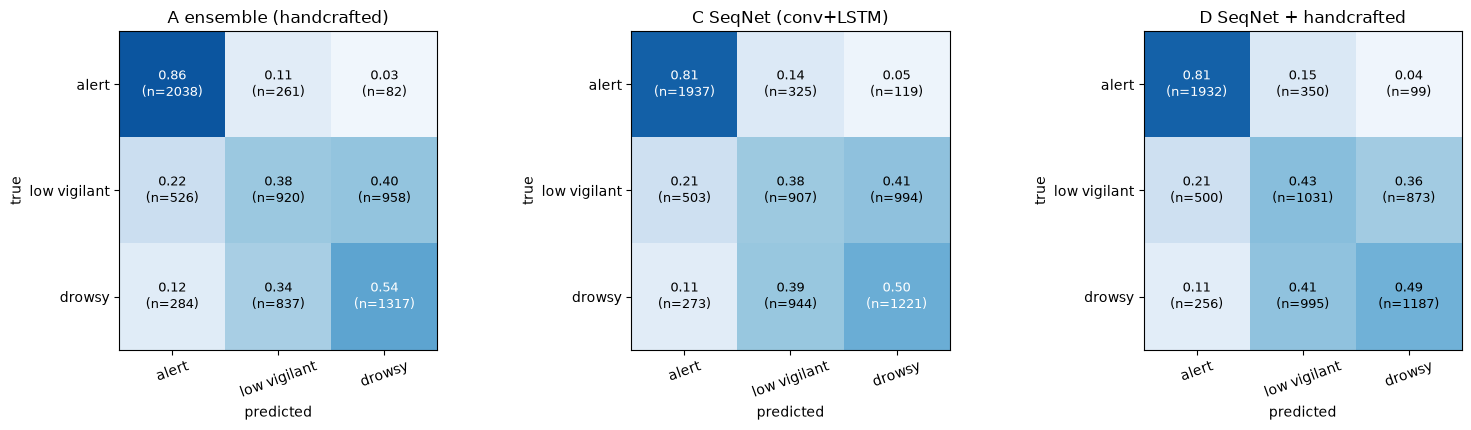

              precision    recall  f1-score   support

       alert      0.714     0.814     0.761      2381
low vigilant      0.417     0.377     0.396      2404
      drowsy      0.523     0.501     0.512      2438

    accuracy                          0.563      7223
   macro avg      0.551     0.564     0.556      7223
weighted avg      0.551     0.563     0.555      7223



In [8]:
show = [k for k in names if k[0] in "ACD"] if RUN_FUSION else [k for k in names if k[0] in "AC"]
fig, ax = plt.subplots(1, len(show), figsize=(5.2 * len(show), 4.4), squeeze=False)
for a, k in zip(ax[0], show):
    plot_cm(y, res[k].argmax(1), a, k)
plt.tight_layout(); plt.savefig(f"{RES}/seq_confusion.png", dpi=150); plt.show()
print(classification_report(y, res[nm["C"]].argmax(1), target_names=LABEL_NAMES, digits=3))

## Reading the results
- **C minus B** is the answer to "does time order matter?" If its interval contains 0, this data does not show that it does.
- **C minus A** compares the learned sequence model with the handcrafted pipeline.
- **D minus A / D minus C** asks whether learned and handcrafted signals are complementary.
- Subjects differ a lot (see notebook 04), so wide intervals are expected. Report what the data support, including "no clear difference".

Outputs: `results/<run>/seq_results.csv`, `seq_paired.csv`, `seq_confusion.png`.